In [120]:
%pip install plotly
import plotly.express as px
import pandas as pd
import seaborn as sns
import duckdb
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


In [73]:
#Start by filtering the Data
olympics = pd.read_csv('olympics.csv')
athletes = duckdb.sql("""SELECT * FROM olympics
                        WHERE GAMES = '2016 Summer' AND Sex = 'M'
                        AND (Sport = 'Basketball' OR Sport = 'Hockey' OR Sport = 'Gymnastics')
                        """).df()

In [74]:
athletes.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Individual All-Around,NaN
1,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Floor Exercise,NaN
2,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Parallel Bars,NaN
3,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Horizontal Bar,NaN
4,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Rings,NaN


<Axes: xlabel='Height', ylabel='Height'>

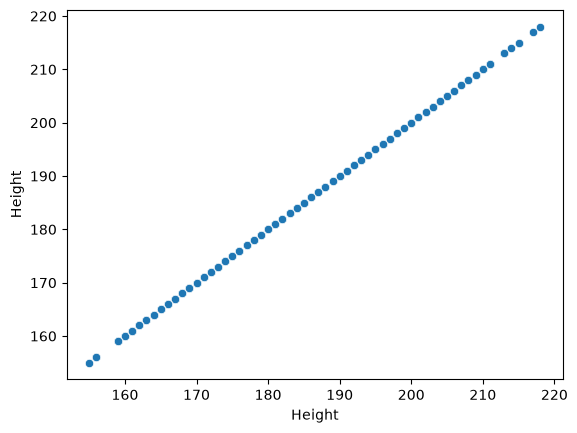

In [75]:
sns.scatterplot(athletes, x='Height', y='Height')

<Axes: xlabel='Height', ylabel='Weight'>

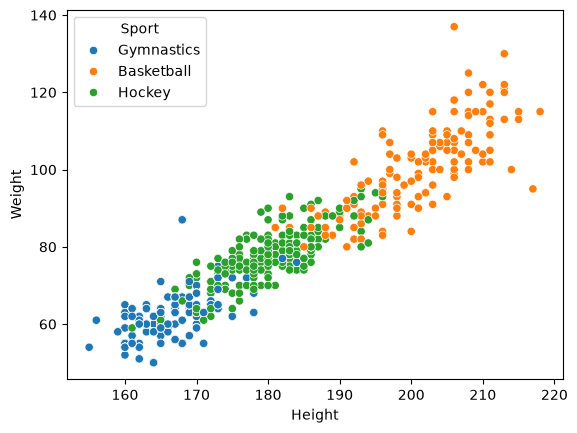

In [76]:
sns.scatterplot(athletes, x='Height', y='Weight', hue='Sport')

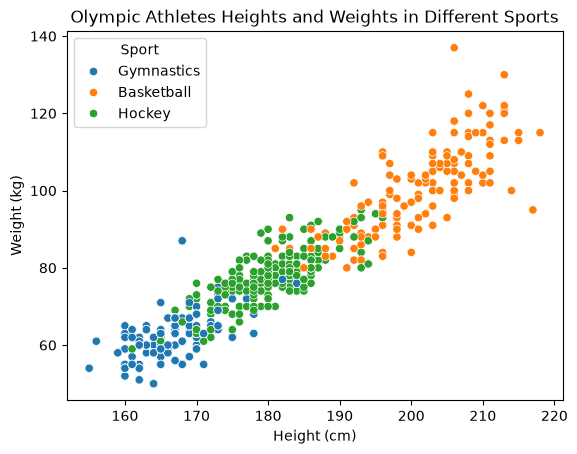

In [77]:
sns.scatterplot(athletes, x='Height', y='Weight', hue='Sport')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Olympic Athletes Heights and Weights in Different Sports')
plt.show()

In [78]:
#Line Plots
#manipulating out dataset
#to display data in line plot form 

athletes_line = duckdb.sql("""
SELECT Year, AVG(Height) AS AvgHeight 
FROM olympics 
WHERE Season = 'Summer' AND Sport = 'Basketball' GROUP BY Year 
ORDER BY Year ASC
""").df()

<Axes: xlabel='Year', ylabel='AvgHeight'>

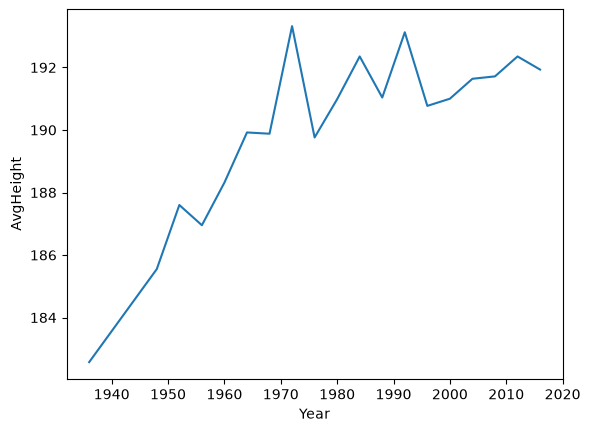

In [79]:
sns.lineplot(athletes_line, x='Year', y='AvgHeight')

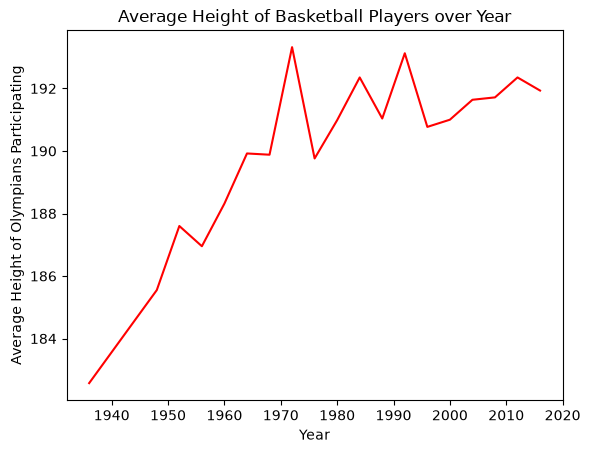

In [80]:
sns.lineplot(athletes_line, x='Year', y='AvgHeight', color = "red")
plt.ylabel("Average Height of Olympians Participating")
plt.title("Average Height of Basketball Players over Year")
plt.show()

In [ ]:
golds = duckdb.sql("""SELECT Team, COUNT(*) AS golds
FROM olympics
WHERE Medal = 'Gold' AND year = '2012'
GROUP BY Team
ORDER BY Golds DESC
LIMIT 10""").df()
golds.head()



,Team,golds
0,United States,139
1,Russia,50
2,China,50
3,Great Britain,46
4,Germany,43


Text(0.5, 1.0, 'Nuber of Gold Medal Athletes Per Country in the 2012 Olympics')

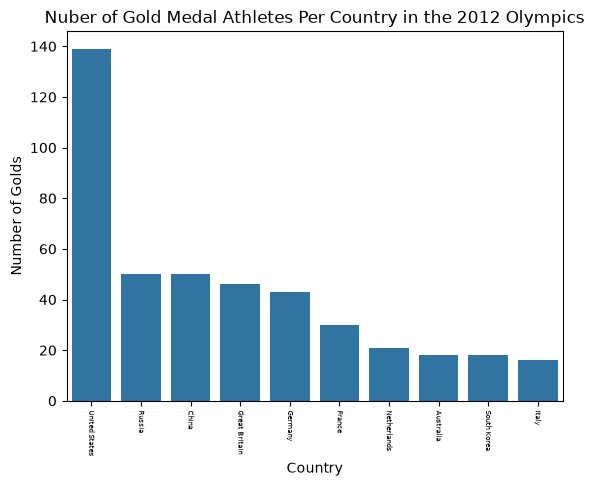

In [82]:
sns.barplot(golds, x='Team', y='golds')
plt.xticks(rotation= -90, fontsize = 5)
plt.xlabel('Country')
plt.ylabel('Number of Golds')
plt.title('Nuber of Gold Medal Athletes Per Country in the 2012 Olympics')

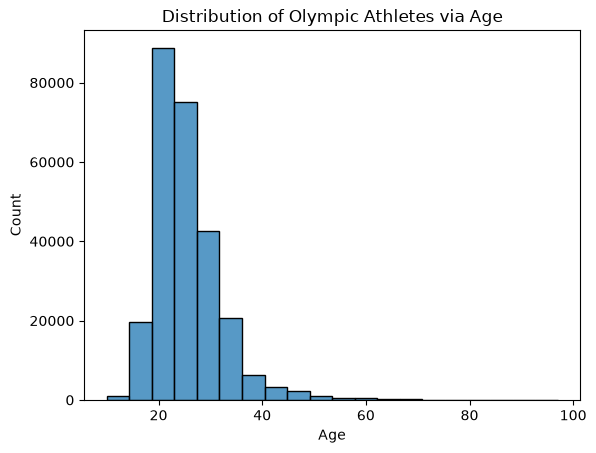

In [85]:
sns.histplot(olympics, x = 'Age', bins = 20)
plt.title('Distribution of Olympic Athletes via Age')
plt.show()

In [101]:
fastest = duckdb.sql("""
SELECT * 
FROM olympics
WHERE Games = '2016 Summer' AND Sex = 'M' AND Event LIKE '% 100 metres%' AND Sport = 'Athletics'
""").df()
fastest['Medal'] = fastest['Medal'].fillna('No Medal')
fastest.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,611,Mohammed Abukhousa,M,23.0,170.0,67.0,Palestine,PLE,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,No Medal
1,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,No Medal
2,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,No Medal
3,1421,Masbah Ahmmed,M,21.0,NaN,NaN,Bangladesh,BAN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,No Medal
4,1488,Harry Leslie Aikines-Aryeetey,M,27.0,180.0,87.0,Great Britain,GBR,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,No Medal


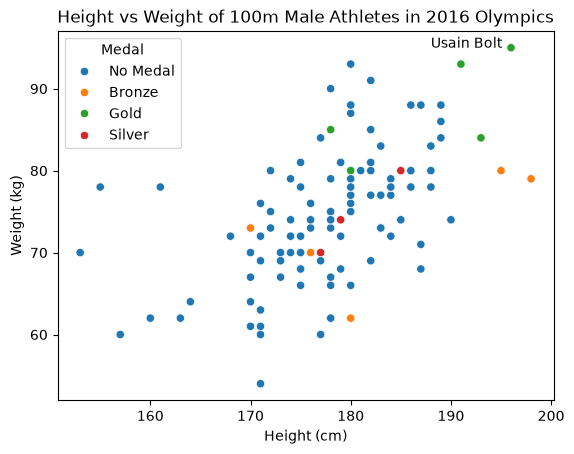

In [107]:
sns.scatterplot(data=fastest, x='Height', y='Weight', hue='Medal')
plt.annotate(text = "Usain Bolt", xy = (188,95))
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Height vs Weight of 100m Male Athletes in 2016 Olympics')
plt.show()

In [121]:
import plotly.express as px


In [122]:
dream_team = duckdb.sql("""SELECT * 
                        FROM olympics 
                        WHERE Games = '1992 Summer' AND SEX = 'M' AND Sport='Basketball' AND Team = 'United States' """).df()

In [123]:
dream_team.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,7901,Charles Wade Barkley,M,29.0,198.0,114.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
1,11668,Larry Joe Bird,M,35.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
2,30009,Clyde Austin Drexler,M,30.0,200.0,101.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
3,33553,Patrick Aloysius Ewing,M,29.0,213.0,109.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
4,55424,"Earvin ""Magic"" Johnson, Jr.",M,32.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold


In [125]:
fig = px.scatter(dream_team,x='Height',y='Weight',text='Name', width=800, height=500)
fig.update_layout(title = '1992 Dream Team Players Heights and Weights', 
xaxis_title='Height (cm)',
yaxis_title='Weight (kg)')
fig.show()   